# EX 4 — Transfer Learning using Pre-Trained Vision Models

**Roll No:** 24BAD002  
**Name:** Abhishek J

**AIM:** To implement transfer learning using pre-trained vision models for image recognition and evaluate their performance on real-world image datasets.

**Dataset:** Dogs vs Cats (Kaggle) — `salader/dogsvscats`

**Models used:**
- ResNet50 (pre-trained on ImageNet, with a new binary classification head)
- Hugging Face pre-trained Vision Transformer (ViT)


## PART A: Dataset Preparation

### Install required libraries

In [1]:
!pip install -q kaggle tensorflow transformers matplotlib pillow


### Configure Kaggle API access

In [2]:
print("Abhishek J - 24BAD002")
import os
from pathlib import Path

kaggle_dir = Path.home() / ".kaggle"
kaggle_file = kaggle_dir / "kaggle.json"

if not kaggle_file.exists():
    from google.colab import files
    uploaded = files.upload()
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_file.write_bytes(uploaded["kaggle.json"])
    kaggle_file.chmod(0o600)

print("Kaggle API configured.")


Saving kaggle.json to kaggle.json
Kaggle API configured.


### Download and extract the dataset from Kaggle

In [3]:
import os
print("Abhishek J - 24BAD002")

dataset_dir = "dogs_vs_cats_data"
os.makedirs(dataset_dir, exist_ok=True)

!kaggle datasets download -d salader/dogsvscats -p dogs_vs_cats_data --unzip

train_dir = os.path.join(dataset_dir, "train")
test_dir = os.path.join(dataset_dir, "test")


print("Dataset downloaded successfully!")
print("Train:", train_dir)
print("Test :", test_dir)


Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:13<00:00, 87.0MB/s]

Dataset downloaded successfully!
Train: dogs_vs_cats_data/train
Test : dogs_vs_cats_data/test


In [4]:
print("Train classes:", os.listdir(train_dir))
print("Test classes :", os.listdir(test_dir))


Train classes: ['cats', 'dogs']
Test classes : ['cats', 'dogs']


### Load and preprocess the dataset

The Kaggle dataset already contains separate `train` and `test` folders, each with
`cats` and `dogs` subfolders. We use 15% of the training data for validation and
keep the Kaggle test set separate for final evaluation.


In [5]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input
print("Abhishek J - 24BAD002")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)


Found 20000 files belonging to 2 classes.
Using 17000 files for training.
Found 20000 files belonging to 2 classes.
Using 3000 files for validation.
Found 5000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


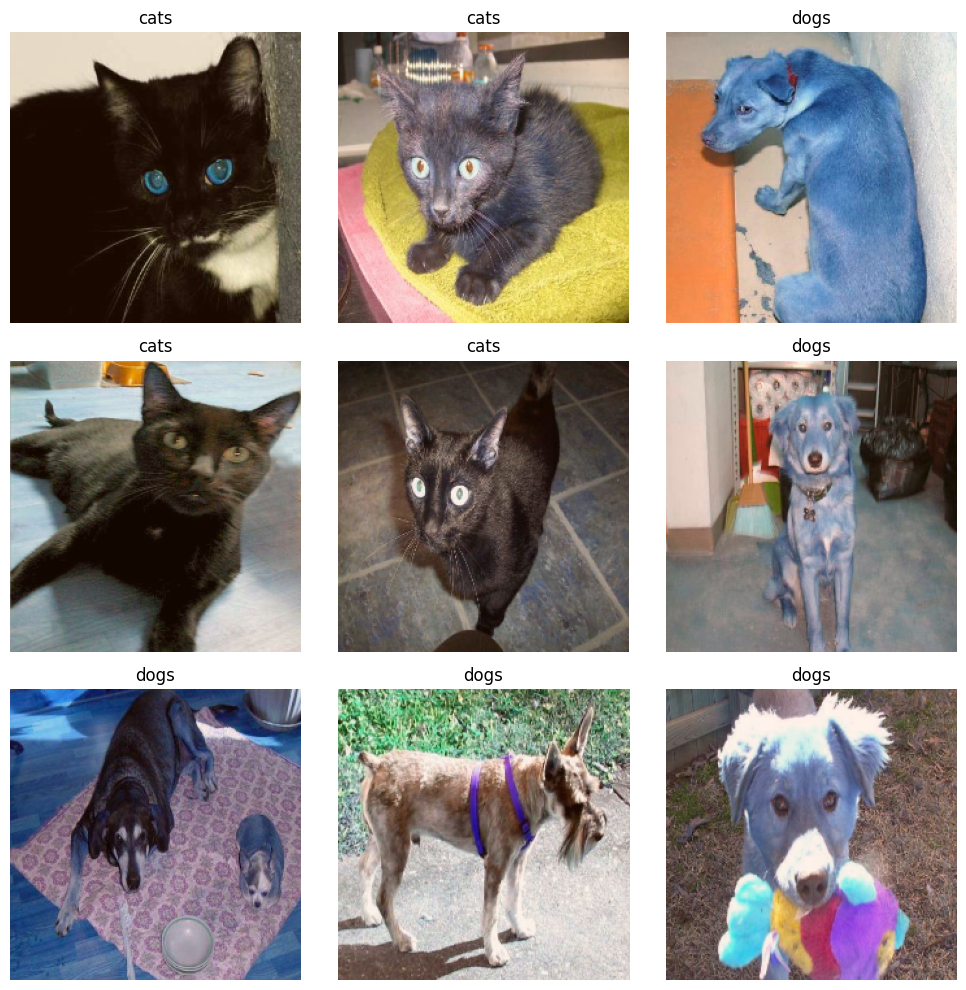

In [6]:
import matplotlib.pyplot as plt
print("Abhishek J - 24BAD002")

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        image = images[i].numpy()
        image = (image - image.min()) / (image.max() - image.min())
        plt.imshow(image)
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")
plt.tight_layout()
plt.show()


## PART B: Implementing Transfer Learning

We load **ResNet50**, pre-trained on ImageNet, remove its original classification
layer, freeze the convolutional base, and add a new binary classification head for cats vs dogs.


In [7]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models
print("Abhishek J - 24BAD002")

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


## PART C: Model Training and Performance Evaluation

In [9]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


Epoch 1/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 92s 147ms/step - accuracy: 0.9745 - loss: 0.0727 - val_accuracy: 0.9883 - val_loss: 0.0370
Epoch 2/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 62s 116ms/step - accuracy: 0.9883 - loss: 0.0330 - val_accuracy: 0.9890 - val_loss: 0.0350
Epoch 3/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 63s 117ms/step - accuracy: 0.9908 - loss: 0.0254 - val_accuracy: 0.9883 - val_loss: 0.0325
Epoch 4/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 63s 119ms/step - accuracy: 0.9927 - loss: 0.0208 - val_accuracy: 0.9873 - val_loss: 0.0333
Epoch 5/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 81s 151ms/step - accuracy: 0.9938 - loss: 0.0181 - val_accuracy: 0.9893 - val_loss: 0.0316
Epoch 6/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 63s 119ms/step - accuracy: 0.9956 - loss: 0.0142 - val_accuracy: 0.9883 - val_loss: 0.0327
Epoch 7/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 66s 124ms/step - accuracy: 0.9956 - loss: 0.0127 - val_accuracy: 0.9890 - val_loss: 0.0336
Epoch 8/10
532/532 ━━━━━━━━━━━━━━━━━━━━ 66s 125ms/step - accuracy: 0.9971 - loss: 0

In [10]:
train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]
train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

print(f"Final Training Accuracy   : {train_acc:.4f}")
print(f"Final Validation Accuracy : {val_acc:.4f}")
print(f"Final Training Loss       : {train_loss:.4f}")
print(f"Final Validation Loss     : {val_loss:.4f}")


Final Training Accuracy   : 0.9981
Final Validation Accuracy : 0.9877
Final Training Loss       : 0.0073
Final Validation Loss     : 0.0368


In [11]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Loss     : {test_loss:.4f}")


157/157 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - accuracy: 0.9896 - loss: 0.0300
Test Accuracy : 0.9896
Test Loss     : 0.0300


### Visualize Accuracy and Loss vs Epoch

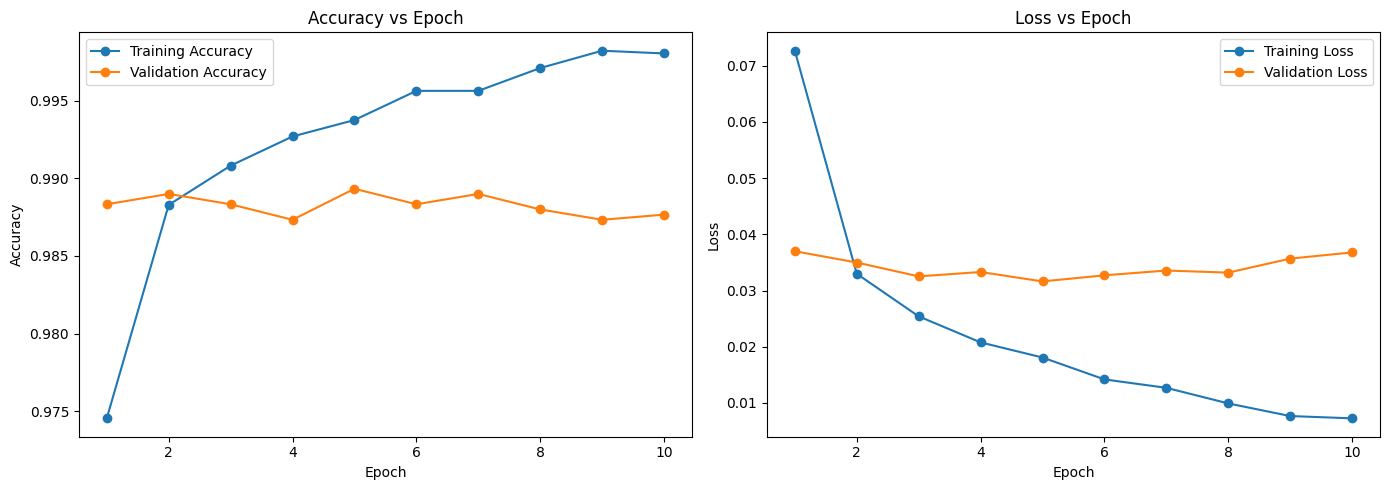

In [12]:
print("Abhishek J - 24BAD002")

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy", marker="o")
plt.plot(epochs_range, val_acc, label="Validation Accuracy", marker="o")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss", marker="o")
plt.plot(epochs_range, val_loss, label="Validation Loss", marker="o")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


## PART D: Using Hugging Face Pre-Trained Models

We load a pre-trained Vision Transformer (**ViT**) from Hugging Face and use it
to classify a few sample images. Its ImageNet predictions are compared with our
ResNet50 transfer-learning predictions.


In [13]:
from transformers import pipeline

hf_classifier = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)


config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

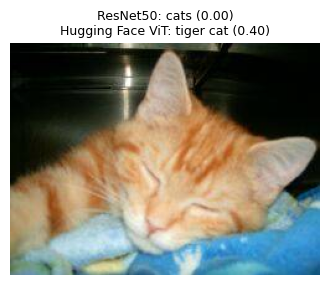

File: cat.9664.jpg
  ResNet50 prediction : cats (score=0.0000)
  Hugging Face ViT    : tiger cat (score=0.4031)
------------------------------------------------------------


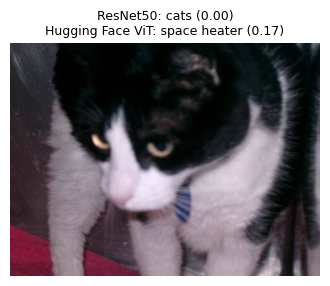

File: cat.11632.jpg
  ResNet50 prediction : cats (score=0.0007)
  Hugging Face ViT    : space heater (score=0.1717)
------------------------------------------------------------


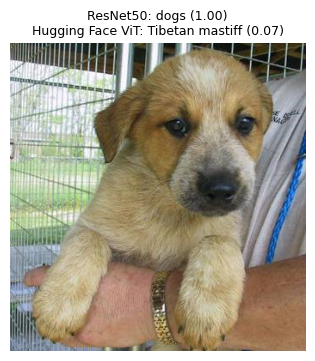

File: dog.7880.jpg
  ResNet50 prediction : dogs (score=1.0000)
  Hugging Face ViT    : Tibetan mastiff (score=0.0671)
------------------------------------------------------------


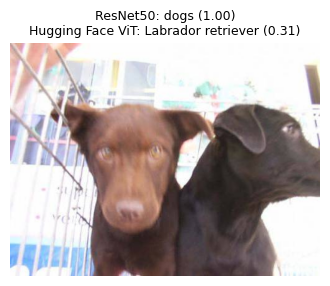

File: dog.9066.jpg
  ResNet50 prediction : dogs (score=1.0000)
  Hugging Face ViT    : Labrador retriever (score=0.3073)
------------------------------------------------------------


In [14]:
import numpy as np
print("Abhishek J - 24BAD002")

from PIL import Image

sample_files = [
    os.path.join(test_dir, "cats", os.listdir(os.path.join(test_dir, "cats"))[0]),
    os.path.join(test_dir, "cats", os.listdir(os.path.join(test_dir, "cats"))[1]),
    os.path.join(test_dir, "dogs", os.listdir(os.path.join(test_dir, "dogs"))[0]),
    os.path.join(test_dir, "dogs", os.listdir(os.path.join(test_dir, "dogs"))[1]),
]

for f in sample_files:
    img = Image.open(f).convert("RGB")

    # ResNet50 prediction
    img_resized = img.resize(IMG_SIZE)
    arr = np.array(img_resized, dtype=np.float32)
    arr = preprocess_input(arr)
    arr = np.expand_dims(arr, axis=0)

    resnet_pred = float(model.predict(arr, verbose=0)[0][0])
    resnet_label = class_names[1] if resnet_pred >= 0.5 else class_names[0]

    # Hugging Face ViT prediction
    hf_result = hf_classifier(img)
    hf_top_label = hf_result[0]["label"]
    hf_top_score = hf_result[0]["score"]

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"ResNet50: {resnet_label} ({resnet_pred:.2f})\n"
        f"Hugging Face ViT: {hf_top_label} ({hf_top_score:.2f})",
        fontsize=9
    )
    plt.show()

    print(f"File: {os.path.basename(f)}")
    print(f"  ResNet50 prediction : {resnet_label} (score={resnet_pred:.4f})")
    print(f"  Hugging Face ViT    : {hf_top_label} (score={hf_top_score:.4f})")

